# Modelado y selección del modelo

El objetivo de este notebook es comparar y optimizar modelos para predecir el abandono de las vendedoras de Glamour, definido como la ausencia de compras durante los seis meses siguientes al mes observado.

Se evaluarán cinco algoritmos: regresión logística, Random Forest, XGBoost, LightGBM y CatBoost. Optuna explorará conjuntamente el tratamiento del desbalance, los hiperparámetros y la ventana de entrenamiento de cada algoritmo, tanto con las variables seleccionadas como con las completas. Se elegirá un único modelo individual.

Las configuraciones se compararán utilizando cuatro bloques de validación temporal, con una brecha de seis meses entre entrenamiento y validación. La métrica principal será el AUC promedio de los cuatro bloques; ante resultados similares, se considerarán el lift mensual del 10 % de mayor riesgo y la simplicidad del modelo.

Al finalizar, se guardará la configuración seleccionada para su posterior evaluación sobre el conjunto OOT.

## 1. Importaciones

Cargamos las herramientas para leer los datos, construir los cinco modelos, aplicar el tratamiento del desbalance y buscar hiperparámetros con Optuna. Todas las funciones del proceso se definen en este notebook.


In [6]:
import hashlib
import json
import os
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

Definimos la ubicación del dataset procesado y de las variables seleccionadas.

In [7]:
ruta_datos = Path("../data/churn_dataset_processed.csv")
ruta_seleccion = Path("../03_variables/variables_seleccionadas.json")

## 3. Protocolo temporal y presupuesto

Conservamos cuatro bloques de validación de cuatro meses, una brecha de seis meses y los últimos cuatro meses como OOT.

La búsqueda no tiene límite de tiempo: continúa hasta alcanzar 1.000 trials completos por estudio.

Hay diez estudios: cinco algoritmos por dos conjuntos de variables. Avanzan por rondas de un trial por estudio, hasta alcanzar 1.000 trials completos por estudio. Cada trial completa los cuatro bloques; no usamos poda ni early stopping. La comparación final usa el mismo número de trials completos por estudio; los trials adicionales de una ronda incompleta quedan guardados para continuar después.

Optuna explora conjuntamente los hiperparámetros, las cuatro estrategias de desbalance y las cuatro ventanas de entrenamiento. Los estudios se ejecutan de uno en uno y cada modelo usa hasta 16 hilos.

Fijamos antes de entrenar las tolerancias de selección: diferencias de AUC hasta 0.001 se consideran un empate práctico; entre esos candidatos se usa el lift, con tolerancia 0.04, y después se prefieren menos variables. Son reglas de decisión, no pruebas de significancia.

In [8]:
MESES_OOT = 4
BRECHA_MESES = 6
NUMERO_BLOQUES = 4
MESES_VALIDACION = 4
COLUMNA_OBJETIVO = "churn"
COLUMNAS_CONTEXTO = ["id_vendedor", "mes_obs", "mes_rank"]

SEMILLA = 42
NUMERO_HILOS = min(16, os.cpu_count() or 1)
MAX_TRIALS_POR_ESTUDIO = 1000
TOLERANCIA_AUC = 0.001
TOLERANCIA_LIFT = 0.04
VENTANAS_ENTRENAMIENTO = {"toda_historia": None, "48_meses": 48, "36_meses": 36, "24_meses": 24}
VERSION_EXPERIMENTO = 2

assert MAX_TRIALS_POR_ESTUDIO > 0
inicio_ejecucion = perf_counter()


## 4. Carga y delimitación de desarrollo

El CSV contiene todas las observaciones etiquetadas. Usamos su último `mes_rank` para ubicar el inicio del OOT y el último mes permitido en desarrollo.

Por ejemplo, si el OOT empieza en diciembre, los seis meses de brecha son junio a noviembre y desarrollo termina en mayo.

`datos_desarrollo` será la entrada para comparar los modelos. Mostramos únicamente conteos y fechas agregadas.

In [9]:
datos = pd.read_csv(ruta_datos, parse_dates=["mes_obs"])

columnas_requeridas = COLUMNAS_CONTEXTO + [COLUMNA_OBJETIVO]
assert set(columnas_requeridas).issubset(datos.columns), "Faltan columnas de contexto u objetivo."
assert not datos.duplicated(["id_vendedor", "mes_obs"]).any(), "Hay vendedoras-mes duplicadas."

ultimo_mes_observado = int(datos["mes_rank"].max())
inicio_oot = ultimo_mes_observado - MESES_OOT + 1
ultimo_mes_desarrollo = inicio_oot - BRECHA_MESES - 1

datos_desarrollo = datos.loc[
    datos["mes_rank"] <= ultimo_mes_desarrollo
].reset_index(drop=True)

assert not datos_desarrollo.empty, "El corte deja el desarrollo vacío."
assert set(datos_desarrollo[COLUMNA_OBJETIVO].unique()) == {0, 1}, "Se esperan las dos clases."

print(f"Desarrollo: {len(datos_desarrollo):,} filas.")
print(
    f"Observaciones: {datos_desarrollo['mes_obs'].min():%Y-%m}"
    f" → {datos_desarrollo['mes_obs'].max():%Y-%m}."
)

Desarrollo: 29,183 filas.
Observaciones: 2016-12 → 2025-05.


## 5. Conjuntos de variables

Prepararemos dos conjuntos para la comparación:
- **Seleccionadas:** los nombres guardados por la fase 03.
- **Completas:** todas las columnas predictoras del dataset procesado.

Los identificadores, las fechas y `churn` se excluyen de los predictores. Los nombres de los conjuntos no dependen de cuántas variables haya; la tabla calcula sus tamaños al ejecutar la celda.

Comprobamos que desarrollo tenga variables numéricas, sin nulos ni infinitos, y que la selección exista en el CSV.

In [ ]:
columnas_excluidas = COLUMNAS_CONTEXTO + [COLUMNA_OBJETIVO]
variables_completas = [
    columna for columna in datos_desarrollo.columns
    if columna not in columnas_excluidas
]

variables_seleccionadas = json.loads(ruta_seleccion.read_text(encoding="utf-8"))["seleccionadas"]

assert variables_seleccionadas, "La selección de variables está vacía."
assert len(variables_seleccionadas) == len(set(variables_seleccionadas)), "La selección tiene duplicados."
assert set(variables_seleccionadas).issubset(variables_completas), "Hay variables seleccionadas ausentes."
assert all(pd.api.types.is_numeric_dtype(datos_desarrollo[columna]) for columna in variables_completas)
assert np.isfinite(datos_desarrollo[variables_completas].to_numpy(dtype=float)).all(), "Hay nulos o infinitos."

conjuntos_variables = {
    "seleccionadas": variables_seleccionadas,
    "completas": variables_completas,
}

display(pd.DataFrame([
    {"conjunto": nombre_conjunto, "numero_variables": len(variables)}
    for nombre_conjunto, variables in conjuntos_variables.items()
]))

,conjunto,numero_variables
0,seleccionadas,6
1,completas,42


## 6. Construcción de los cuatro bloques

Los bloques de validación cubren los últimos 16 meses del desarrollo. En cada vuelta del bucle:

1. Calculamos el inicio y el fin de la validación.
2. Retrocedemos seis meses completos para delimitar el entrenamiento.
3. Guardamos los índices de las filas de entrenamiento y validación.
4. Comprobamos que los conjuntos tengan datos, dos clases y la separación temporal esperada.

`bloques_temporales` contiene las cuatro parejas de índices que usarán los modelos. `tabla_bloques` permite auditar las fechas y los tamaños.

In [11]:
meses_desarrollo = datos_desarrollo["mes_rank"].to_numpy()
primer_mes_validacion = (
    int(meses_desarrollo.max()) - NUMERO_BLOQUES * MESES_VALIDACION + 1
)

bloques_temporales = []
resumen_bloques = []

for numero_bloque in range(NUMERO_BLOQUES):
    inicio_validacion = primer_mes_validacion + numero_bloque * MESES_VALIDACION
    fin_validacion = inicio_validacion + MESES_VALIDACION - 1
    fin_entrenamiento = inicio_validacion - BRECHA_MESES - 1

    indices_entrenamiento = np.flatnonzero(meses_desarrollo <= fin_entrenamiento)
    indices_validacion = np.flatnonzero(
        (meses_desarrollo >= inicio_validacion) & (meses_desarrollo <= fin_validacion)
    )

    assert len(indices_entrenamiento) > 0 and len(indices_validacion) > 0, "Hay un bloque vacío."
    entrenamiento = datos_desarrollo.iloc[indices_entrenamiento]
    validacion = datos_desarrollo.iloc[indices_validacion]
    assert entrenamiento["mes_rank"].max() + BRECHA_MESES < validacion["mes_rank"].min()
    assert entrenamiento[COLUMNA_OBJETIVO].nunique() == 2, "Falta una clase en entrenamiento."
    assert validacion[COLUMNA_OBJETIVO].nunique() == 2, "Falta una clase en validación."

    bloques_temporales.append((indices_entrenamiento, indices_validacion))
    resumen_bloques.append({
        "bloque": numero_bloque + 1,
        "entrenamiento_desde": entrenamiento["mes_obs"].min().strftime("%Y-%m"),
        "entrenamiento_hasta": entrenamiento["mes_obs"].max().strftime("%Y-%m"),
        "validacion_desde": validacion["mes_obs"].min().strftime("%Y-%m"),
        "validacion_hasta": validacion["mes_obs"].max().strftime("%Y-%m"),
        "filas_entrenamiento": len(entrenamiento),
        "filas_validacion": len(validacion),
    })

tabla_bloques = pd.DataFrame(resumen_bloques)
display(tabla_bloques)

,bloque,entrenamiento_desde,entrenamiento_hasta,validacion_desde,validacion_hasta,filas_entrenamiento,filas_validacion
0,1,2016-12,2023-07,2024-02,2024-05,23426,1006
1,2,2016-12,2023-11,2024-06,2024-09,24594,1110
2,3,2016-12,2024-03,2024-10,2025-01,25637,1039
3,4,2016-12,2024-07,2025-02,2025-05,26695,872


## 7. Evaluación temporal del modelo

Cada bloque recibe una copia nueva del modelo. Si se usa una ventana reciente, se recorta únicamente su entrenamiento; las filas de validación y la brecha se conservan.

El pipeline ajusta el escalado y el remuestreo solo con entrenamiento. La regresión logística se estandariza; SMOTE también necesita escalado porque construye vecinos mediante distancias. Los demás modelos no requieren escalado.

Con pesos de clase, el peso positivo se calcula en cada entrenamiento como:

    peso = 1 + intensidad_peso × (negativos / positivos − 1)

Una intensidad de 0 equivale a no ponderar y una de 1 al peso balanceado. Optuna buscará valores intermedios en los trials que utilicen pesos de clase.

Se conservan las probabilidades de validación en su posición original. Estas predicciones fuera de entrenamiento, llamadas OOF, permiten conservar y auditar los resultados de validación. La función devuelve AUC por bloque, promedio, desviación, lift mensual y probabilidades OOF. La desviación entre bloques no es un intervalo de confianza.

La función de lift se define en la sección 8, antes de la primera llamada a evaluar_modelo.

In [12]:
def preparar_modelo(modelo, objetivo_entrenamiento, estrategia, intensidad_peso=1.0):
    modelo = clone(modelo)
    estrategias = {"sin_tratamiento", "pesos_clase", "submuestreo", "smote"}
    if estrategia not in estrategias:
        raise ValueError(f"Estrategia desconocida: {estrategia}")

    if estrategia == "pesos_clase":
        assert 0 <= intensidad_peso <= 1
        positivos = int((objetivo_entrenamiento == 1).sum())
        negativos = int((objetivo_entrenamiento == 0).sum())
        peso = 1 + intensidad_peso * (negativos / positivos - 1)
        if isinstance(modelo, (LogisticRegression, RandomForestClassifier)):
            modelo.set_params(class_weight={0: 1.0, 1: peso})
        else:
            modelo.set_params(scale_pos_weight=peso)

    pasos = []
    if isinstance(modelo, LogisticRegression) or estrategia == "smote":
        pasos.append(("escalado", StandardScaler()))
    if estrategia == "submuestreo":
        pasos.append(("muestreo", RandomUnderSampler(random_state=SEMILLA)))
    elif estrategia == "smote":
        vecinos = min(5, int(objetivo_entrenamiento.value_counts().min()) - 1)
        assert vecinos >= 1, "SMOTE necesita al menos dos ejemplos de cada clase."
        pasos.append(("muestreo", SMOTE(k_neighbors=vecinos, random_state=SEMILLA)))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)


def resumir_probabilidades(probabilidades_oof):
    probabilidades_oof = np.asarray(probabilidades_oof, dtype=float)
    assert probabilidades_oof.shape == (len(datos_desarrollo),)
    indices_evaluados = np.concatenate([validacion for _, validacion in bloques_temporales])
    assert len(indices_evaluados) == len(np.unique(indices_evaluados))
    assert np.isfinite(probabilidades_oof[indices_evaluados]).all()
    assert ((probabilidades_oof[indices_evaluados] >= 0) &
            (probabilidades_oof[indices_evaluados] <= 1)).all()

    auc_por_bloque = [
        float(roc_auc_score(
            datos_desarrollo.iloc[indices_validacion][COLUMNA_OBJETIVO],
            probabilidades_oof[indices_validacion],
        ))
        for _, indices_validacion in bloques_temporales
    ]
    resultado_lift = calcular_lift_mensual(
        datos_desarrollo.iloc[indices_evaluados], probabilidades_oof[indices_evaluados]
    )
    return {
        "auc_por_bloque": auc_por_bloque,
        "auc_promedio": float(np.mean(auc_por_bloque)),
        "desviacion_auc": float(np.std(auc_por_bloque)),
        "lift_por_mes": resultado_lift["lift_por_mes"],
        "lift_promedio": resultado_lift["lift_promedio"],
        "probabilidades_oof": probabilidades_oof,
    }


def recortar_entrenamiento(datos_entrenamiento, ventana_meses=None):
    if ventana_meses is not None:
        assert ventana_meses > 0
        ultimo_mes = datos_entrenamiento["mes_rank"].max()
        datos_entrenamiento = datos_entrenamiento.loc[
            datos_entrenamiento["mes_rank"] > ultimo_mes - ventana_meses
        ]
    assert datos_entrenamiento[COLUMNA_OBJETIVO].nunique() == 2
    return datos_entrenamiento


def evaluar_modelo(
    modelo, variables, estrategia="sin_tratamiento",
    ventana_meses=None, intensidad_peso=1.0,
):
    probabilidades_oof = np.full(len(datos_desarrollo), np.nan)
    for indices_entrenamiento, indices_validacion in bloques_temporales:
        datos_entrenamiento = recortar_entrenamiento(
            datos_desarrollo.iloc[indices_entrenamiento], ventana_meses
        )
        datos_validacion = datos_desarrollo.iloc[indices_validacion]
        modelo_bloque = preparar_modelo(
            modelo, datos_entrenamiento[COLUMNA_OBJETIVO], estrategia, intensidad_peso
        )
        modelo_bloque.fit(
            datos_entrenamiento[variables], datos_entrenamiento[COLUMNA_OBJETIVO]
        )
        probabilidades_oof[indices_validacion] = modelo_bloque.predict_proba(
            datos_validacion[variables]
        )[:, 1]
    return resumir_probabilidades(probabilidades_oof)

## 8. Lift mensual del 10 % de mayor riesgo

El lift mide cuánto churn concentra la selección del modelo respecto de la tasa de churn del mes:

```text
Lift = proporción de churn entre las seleccionadas / proporción de churn del mes
```

Por ejemplo, si el 30 % de las vendedoras del mes abandona y entre las seleccionadas abandona el 60 %, el lift es 2.

La función recibe las filas de validación y sus probabilidades predichas. Dentro de cada mes selecciona el 10 % con mayor probabilidad, redondeando el número de contactos hacia abajo y tomando al menos una fila. Devuelve una tabla por mes y el promedio de los lifts, con el mismo peso para cada mes.

Si un mes no tiene abandonos, su lift queda como `NaN` porque el denominador es cero, y se excluye del promedio. Las probabilidades deben corresponder al mismo orden de filas de `datos_validacion`.

In [13]:
def calcular_lift_mensual(datos_validacion, probabilidades, proporcion=0.10):
    assert 0 < proporcion <= 1, "La proporción debe estar entre 0 y 1, excluyendo 0."
    assert not datos_validacion.empty, "Se necesitan filas de validación."

    resultados = datos_validacion[["mes_obs", COLUMNA_OBJETIVO]].copy()
    resultados["probabilidad"] = np.asarray(probabilidades, dtype=float)
    assert np.isfinite(resultados["probabilidad"]).all(), "Hay probabilidades nulas o infinitas."
    resumen_mensual = []

    for mes, datos_mes in resultados.groupby("mes_obs"):
        numero_contactos = max(1, int(len(datos_mes) * proporcion))
        seleccionadas = datos_mes.nlargest(numero_contactos, "probabilidad")

        tasa_churn_mes = datos_mes[COLUMNA_OBJETIVO].mean()
        precision_seleccionadas = seleccionadas[COLUMNA_OBJETIVO].mean()
        lift = precision_seleccionadas / tasa_churn_mes if tasa_churn_mes > 0 else np.nan

        resumen_mensual.append({
            "mes": mes,
            "filas_validacion": len(datos_mes),
            "seleccionadas": numero_contactos,
            "tasa_churn_mes": tasa_churn_mes,
            "precision_seleccionadas": precision_seleccionadas,
            "lift": lift,
        })

    tabla_lift = pd.DataFrame(resumen_mensual)
    return {
        "lift_por_mes": tabla_lift,
        "lift_promedio": float(tabla_lift["lift"].mean()),
    }

## 9. Primer modelo de referencia

Usamos XGBoost con las variables seleccionadas en la fase 03 y la configuración base del notebook original: 300 árboles, profundidad máxima de 4 y tasa de aprendizaje de 0.05.

`scale_pos_weight=1.0` da el mismo peso a ambas clases. Este resultado ofrece una referencia de desempeño antes de la optimización conjunta con Optuna. Los hiperparámetros son fijos en esta etapa.

Al ejecutar esta celda, `evaluar_modelo` entrena una copia por bloque y devuelve los resultados de validación. Mostramos el AUC por bloque, el promedio y la desviación, junto con el lift mensual. El redondeo se aplica únicamente al mostrar los resultados.

In [14]:
modelo_referencia = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=1.0,
    tree_method="hist",
    n_jobs=NUMERO_HILOS,
    random_state=SEMILLA,
    verbosity=0,
)

resultado_referencia = evaluar_modelo(modelo_referencia, variables_seleccionadas)

tabla_auc_referencia = pd.DataFrame({
    "bloque": range(1, len(resultado_referencia["auc_por_bloque"]) + 1),
    "auc": resultado_referencia["auc_por_bloque"],
})

print(f"XGBoost de referencia con {len(variables_seleccionadas)} variables, sin ponderar.")
print(f"AUC promedio: {resultado_referencia['auc_promedio']:.4f}")
print(f"Desviación del AUC: {resultado_referencia['desviacion_auc']:.4f}")
print(f"Lift mensual promedio: {resultado_referencia['lift_promedio']:.2f}")
display(tabla_auc_referencia.round(4))
display(resultado_referencia["lift_por_mes"].round(4))

XGBoost de referencia con 6 variables, sin ponderar.
AUC promedio: 0.7873
Desviación del AUC: 0.0072
Lift mensual promedio: 2.32


,bloque,auc
0,1,0.7960
1,2,0.7844
2,3,0.7917
3,4,0.7770


,mes,filas_validacion,seleccionadas,tasa_churn_mes,precision_seleccionadas,lift
0,2024-02-01,239,23,0.2385,0.3913,1.6407
1,2024-03-01,242,24,0.2893,0.6250,2.1607
2,2024-04-01,258,25,0.3178,0.8000,2.5171
3,2024-05-01,267,26,0.2846,0.7308,2.5673
4,2024-06-01,250,25,0.2240,0.6400,2.8571
5,2024-07-01,283,28,0.2580,0.7857,3.0460
6,2024-08-01,296,29,0.2905,0.6207,2.1363
7,2024-09-01,281,28,0.3381,0.6429,1.9015
8,2024-10-01,247,24,0.2672,0.7500,2.8068
9,2024-11-01,265,26,0.3245,0.7308,2.2518


## 10. Criterios de selección y estrategias para Optuna

Definimos las funciones de resumen y selección que se usarán para comparar los modelos finales.

Optuna explorará cuatro estrategias junto con los hiperparámetros y la ventana de entrenamiento:

- **Sin tratamiento:** conserva las filas y da el mismo peso a ambas clases.
- **Pesos de clase:** pondera las clases del entrenamiento con una intensidad elegida por Optuna.
- **Submuestreo:** reduce aleatoriamente la clase mayoritaria hasta equilibrar las clases.
- **SMOTE:** estandariza las variables y crea ejemplos sintéticos de la clase minoritaria hasta equilibrarlas.

La validación conserva todas sus filas y su distribución original. No se realiza una comparación preliminar de estas estrategias.


In [ ]:
def elegir_candidato(tabla, columnas_simplicidad):
    assert not tabla.empty
    assert np.isfinite(tabla[["auc_promedio", "lift_promedio"]].to_numpy()).all()
    candidatos = tabla.loc[
        tabla["auc_promedio"] >= tabla["auc_promedio"].max() - TOLERANCIA_AUC
    ]
    candidatos = candidatos.loc[
        candidatos["lift_promedio"] >= candidatos["lift_promedio"].max() - TOLERANCIA_LIFT
    ]
    return candidatos.sort_values(
        columnas_simplicidad + ["auc_promedio", "lift_promedio"],
        ascending=[True] * len(columnas_simplicidad) + [False, False],
        kind="stable",
    ).iloc[0]


def metricas_resumen(resultado):
    return {
        "auc_promedio": resultado["auc_promedio"],
        "desviacion_auc": resultado["desviacion_auc"],
        "lift_promedio": resultado["lift_promedio"],
    }


estrategias_desbalance = ["sin_tratamiento", "pesos_clase", "submuestreo", "smote"]


## 11. Modelos y espacios de búsqueda

Cada algoritmo tendrá dos estudios: variables seleccionadas y variables completas. En cada trial, Optuna elige simultáneamente:

- Una estrategia: sin tratamiento, pesos de clase, submuestreo o SMOTE.
- Una ventana de entrenamiento: toda la historia, 48, 36 o 24 meses.
- Los hiperparámetros del algoritmo, según los rangos siguientes.
- La intensidad del peso entre 0 y 1, cuando la estrategia utiliza pesos de clase.

Cada estudio comienza probando las 16 combinaciones de estrategia y ventana, con hiperparámetros propuestos por el sampler. Después continúa la búsqueda adaptativa con TPE. Esto permite encontrar interacciones que la selección por etapas dejaba fuera.

Los reales con log se exploran en escala logarítmica. En regresión logística, l1_ratio de 0 corresponde a L2 y de 1 a L1. El AUC promedio de los cuatro bloques es el objetivo.

In [16]:
ALGORITMOS = ["logreg", "random_forest", "xgboost", "lightgbm", "catboost"]

espacios_busqueda = {
    "logreg": {
        "C": ("real", {"low": 1e-3, "high": 1e2, "log": True}),
        "l1_ratio": ("categorico", [0.0, 1.0]),
    },
    "random_forest": {
        "n_estimators": ("entero", {"low": 100, "high": 500, "step": 100}),
        "max_depth": ("entero", {"low": 3, "high": 16}),
        "min_samples_leaf": ("entero", {"low": 1, "high": 100, "log": True}),
        "max_features": ("categorico", ["sqrt", 0.3, 0.5, 1.0]),
    },
    "xgboost": {
        "n_estimators": ("entero", {"low": 100, "high": 1000, "step": 50}),
        "learning_rate": ("real", {"low": 0.01, "high": 0.3, "log": True}),
        "max_depth": ("entero", {"low": 2, "high": 8}),
        "min_child_weight": ("real", {"low": 1, "high": 50, "log": True}),
        "subsample": ("real", {"low": 0.5, "high": 1.0}),
        "colsample_bytree": ("real", {"low": 0.5, "high": 1.0}),
        "gamma": ("real", {"low": 0.0, "high": 5.0}),
        "reg_lambda": ("real", {"low": 1e-3, "high": 10, "log": True}),
        "reg_alpha": ("real", {"low": 1e-3, "high": 10, "log": True}),
    },
    "lightgbm": {
        "n_estimators": ("entero", {"low": 100, "high": 1000, "step": 50}),
        "learning_rate": ("real", {"low": 0.01, "high": 0.3, "log": True}),
        "num_leaves": ("entero", {"low": 4, "high": 128, "log": True}),
        "min_child_samples": ("entero", {"low": 5, "high": 200, "log": True}),
        "subsample": ("real", {"low": 0.5, "high": 1.0}),
        "colsample_bytree": ("real", {"low": 0.5, "high": 1.0}),
        "reg_lambda": ("real", {"low": 1e-3, "high": 10, "log": True}),
        "reg_alpha": ("real", {"low": 1e-3, "high": 10, "log": True}),
    },
    "catboost": {
        "iterations": ("entero", {"low": 100, "high": 1000, "step": 50}),
        "learning_rate": ("real", {"low": 0.01, "high": 0.3, "log": True}),
        "depth": ("entero", {"low": 3, "high": 8}),
        "l2_leaf_reg": ("real", {"low": 1, "high": 30, "log": True}),
        "random_strength": ("real", {"low": 0.0, "high": 5.0}),
        "bagging_temperature": ("real", {"low": 0.0, "high": 1.0}),
    },
}


def sugerir_parametros(trial, algoritmo, estrategia):
    parametros = {}
    for nombre, (tipo, opciones) in espacios_busqueda[algoritmo].items():
        if tipo == "real":
            parametros[nombre] = trial.suggest_float(nombre, **opciones)
        elif tipo == "entero":
            parametros[nombre] = trial.suggest_int(nombre, **opciones)
        else:
            parametros[nombre] = trial.suggest_categorical(nombre, opciones)
    if estrategia == "pesos_clase":
        parametros["intensidad_peso"] = trial.suggest_float("intensidad_peso", 0.0, 1.0)
    return parametros


def construir_modelo(algoritmo, parametros):
    parametros = dict(parametros)
    parametros.pop("intensidad_peso", None)
    if algoritmo == "logreg":
        return LogisticRegression(
            solver="liblinear", max_iter=5000, random_state=SEMILLA, **parametros
        )
    if algoritmo == "random_forest":
        return RandomForestClassifier(
            n_jobs=NUMERO_HILOS, random_state=SEMILLA, **parametros
        )
    if algoritmo == "xgboost":
        return XGBClassifier(
            tree_method="hist", scale_pos_weight=1.0, n_jobs=NUMERO_HILOS,
            random_state=SEMILLA, verbosity=0, **parametros
        )
    if algoritmo == "lightgbm":
        return LGBMClassifier(
            subsample_freq=1, scale_pos_weight=1.0, n_jobs=NUMERO_HILOS,
            random_state=SEMILLA, verbosity=-1, **parametros
        )
    if algoritmo == "catboost":
        return CatBoostClassifier(
            scale_pos_weight=1.0, thread_count=NUMERO_HILOS, random_seed=SEMILLA,
            verbose=False, allow_writing_files=False, **parametros
        )
    raise ValueError(f"Algoritmo desconocido: {algoritmo}")

## 12. Búsqueda conjunta con Optuna y guardado del progreso

Cada experimento tiene una carpeta dentro de resultados_v2. Su identificador depende de los datos de desarrollo, el protocolo, las variables, los espacios de búsqueda, las versiones de las librerías y el código guardado. Guarda el notebook antes de ejecutarlo.

SQLite conserva cada trial terminado. Si vuelves a ejecutar todo, se continúa el experimento compatible hasta alcanzar MAX_TRIALS_POR_ESTUDIO, sin límite de tiempo. El máximo de trials se excluye del identificador. La secuencia de sugerencias al reanudar puede diferir de una ejecución continua.

Una ronda completa añade un trial a cada estudio. La búsqueda termina cuando todos los estudios alcanzan MAX_TRIALS_POR_ESTUDIO. Se comparan únicamente los primeros N trials completos de cada estudio, donde N es el menor número disponible entre los diez. Así el presupuesto efectivo de la comparación es igual.

In [ ]:
versiones_librerias = {
    nombre: version(nombre)
    for nombre in [
        "numpy", "pandas", "scikit-learn", "imbalanced-learn",
        "xgboost", "lightgbm", "catboost", "optuna",
    ]
}

notebook_guardado = json.loads(Path("modelado_v2.ipynb").read_text(encoding="utf-8"))
codigo_guardado = {
    celda["id"]: "".join(celda["source"])
    for celda in notebook_guardado["cells"]
    if celda["cell_type"] == "code" and celda["id"] != "protocolo"
}
huella_codigo = hashlib.sha256(
    json.dumps(codigo_guardado, sort_keys=True).encode()
).hexdigest()
huella_datos = hashlib.sha256(
    pd.util.hash_pandas_object(datos_desarrollo, index=True).to_numpy().tobytes()
).hexdigest()

protocolo_experimento = {
    "version": VERSION_EXPERIMENTO,
    "huella_codigo": huella_codigo,
    "huella_datos_desarrollo": huella_datos,
    "columnas": datos_desarrollo.columns.tolist(),
    "columna_objetivo": COLUMNA_OBJETIVO,
    "columnas_contexto": COLUMNAS_CONTEXTO,
    "ultimo_mes_desarrollo": ultimo_mes_desarrollo,
    "meses_oot": MESES_OOT,
    "brecha_meses": BRECHA_MESES,
    "numero_bloques": NUMERO_BLOQUES,
    "meses_validacion": MESES_VALIDACION,
    "bloques": tabla_bloques.to_dict(orient="records"),
    "semilla": SEMILLA,
    "numero_hilos": NUMERO_HILOS,
    "variables": conjuntos_variables,
    "estrategias_desbalance": estrategias_desbalance,
    "busqueda": "conjunta_desbalance_ventana_hiperparametros",
    "espacios_busqueda": espacios_busqueda,
    "ventanas_entrenamiento": VENTANAS_ENTRENAMIENTO,
    "tolerancia_auc": TOLERANCIA_AUC,
    "tolerancia_lift": TOLERANCIA_LIFT,
    "versiones_librerias": versiones_librerias,
}
texto_protocolo = json.dumps(protocolo_experimento, sort_keys=True, ensure_ascii=False)
identificador_experimento = hashlib.sha256(texto_protocolo.encode()).hexdigest()[:16]

carpeta_resultados = Path("resultados_v2") / identificador_experimento
carpeta_trials = carpeta_resultados / "trials"
carpeta_predicciones = carpeta_resultados / "predicciones"
for carpeta in [carpeta_resultados, carpeta_trials, carpeta_predicciones]:
    carpeta.mkdir(parents=True, exist_ok=True)

ruta_protocolo = carpeta_resultados / "protocolo.json"
if ruta_protocolo.exists():
    assert json.loads(ruta_protocolo.read_text()) == json.loads(texto_protocolo)
else:
    ruta_protocolo.write_text(texto_protocolo, encoding="utf-8")

ruta_base_optuna = carpeta_resultados / "optuna.db"
almacenamiento_optuna = f"sqlite:///{ruta_base_optuna.resolve().as_posix()}"
tabla_bloques.to_csv(carpeta_resultados / "bloques.csv", index=False)
print(f"Resultados y progreso: {carpeta_resultados.resolve()}")

In [18]:
def evaluar_configuracion(configuracion):
    firma = hashlib.sha256(
        json.dumps(configuracion, sort_keys=True).encode()
    ).hexdigest()
    ruta_predicciones = carpeta_predicciones / f"{firma}.npz"
    if ruta_predicciones.exists():
        with np.load(ruta_predicciones, allow_pickle=False) as guardado:
            probabilidades = guardado["probabilidades_oof"].copy()
        return resumir_probabilidades(probabilidades)

    resultado = evaluar_modelo(
        construir_modelo(configuracion["algoritmo"], configuracion["parametros"]),
        configuracion["variables"],
        estrategia=configuracion["estrategia"],
        ventana_meses=configuracion["ventana_meses"],
        intensidad_peso=configuracion["parametros"].get("intensidad_peso", 1.0),
    )
    ruta_temporal = ruta_predicciones.with_suffix(".tmp.npz")
    np.savez_compressed(
        ruta_temporal, probabilidades_oof=resultado["probabilidades_oof"]
    )
    ruta_temporal.replace(ruta_predicciones)
    return resultado

In [19]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
estudios = {}
configuraciones_optuna = {}
resultados_optuna = {}
filas_optuna = []


def crear_objetivo(algoritmo, variables):
    def objetivo(trial):
        estrategia = trial.suggest_categorical("estrategia", estrategias_desbalance)
        ventana = trial.suggest_categorical("ventana", list(VENTANAS_ENTRENAMIENTO))
        parametros = sugerir_parametros(trial, algoritmo, estrategia)
        resultado = evaluar_modelo(
            construir_modelo(algoritmo, parametros),
            variables,
            estrategia=estrategia,
            ventana_meses=VENTANAS_ENTRENAMIENTO[ventana],
            intensidad_peso=parametros.get("intensidad_peso", 1.0),
        )
        trial.set_user_attr("auc_por_bloque", resultado["auc_por_bloque"])
        trial.set_user_attr("desviacion_auc", resultado["desviacion_auc"])
        trial.set_user_attr("lift_promedio", resultado["lift_promedio"])
        return resultado["auc_promedio"]
    return objetivo


def trials_completos(estudio):
    return estudio.get_trials(
        deepcopy=False, states=(optuna.trial.TrialState.COMPLETE,)
    )


objetivos = {}
for algoritmo in ALGORITMOS:
    for conjunto, variables in conjuntos_variables.items():
        nombre_estudio = f"{algoritmo}__{conjunto}"
        estudio = optuna.create_study(
            study_name=nombre_estudio,
            storage=almacenamiento_optuna,
            direction="maximize",
            load_if_exists=True,
            sampler=optuna.samplers.TPESampler(seed=SEMILLA, n_startup_trials=32),
            pruner=optuna.pruners.NopPruner(),
        )
        if not estudio.get_trials(deepcopy=False):
            combinaciones_iniciales = [
                {"estrategia": estrategia, "ventana": ventana}
                for estrategia in estrategias_desbalance
                for ventana in VENTANAS_ENTRENAMIENTO
            ]
            orden_inicial = np.random.default_rng(SEMILLA).permutation(
                len(combinaciones_iniciales)
            )
            for indice in orden_inicial:
                estudio.enqueue_trial(combinaciones_iniciales[indice])
        estudios[nombre_estudio] = estudio
        objetivos[nombre_estudio] = crear_objetivo(algoritmo, variables)

print(
    f"Búsqueda conjunta sin límite de tiempo: {MAX_TRIALS_POR_ESTUDIO} trials por estudio.",
    flush=True,
)

while True:
    cantidades = {
        nombre: len(trials_completos(estudio))
        for nombre, estudio in estudios.items()
    }
    nivel = min(cantidades.values())
    if nivel >= MAX_TRIALS_POR_ESTUDIO:
        break

    for nombre, estudio in estudios.items():
        if cantidades[nombre] != nivel:
            continue
        estudio.optimize(
            objetivos[nombre], n_trials=1, n_jobs=1, gc_after_trial=True
        )

    minimo_actual = min(len(trials_completos(estudio)) for estudio in estudios.values())
    print(
        f"Trials comparables por estudio: {minimo_actual}; "
        f"tiempo total: {(perf_counter() - inicio_ejecucion) / 60:.1f} min.",
        flush=True,
    )

trials_comparables = min(len(trials_completos(estudio)) for estudio in estudios.values())
assert trials_comparables > 0, (
    "No hay un trial completo en todos los estudios. El progreso está guardado; "
    "reinicia la ejecución para continuar hasta alcanzar el máximo de trials."
)
print(f"Selección con los primeros {trials_comparables} trials completos por estudio.")

for algoritmo in ALGORITMOS:
    for conjunto, variables in conjuntos_variables.items():
        nombre_estudio = f"{algoritmo}__{conjunto}"
        estudio = estudios[nombre_estudio]
        estudio.trials_dataframe().to_csv(
            carpeta_trials / f"{nombre_estudio}.csv", index=False
        )
        trials_elegibles = trials_completos(estudio)[:trials_comparables]
        mejor_trial = max(
            trials_elegibles,
            key=lambda trial: (
                trial.value, trial.user_attrs["lift_promedio"], -trial.number
            ),
        )
        parametros = dict(mejor_trial.params)
        estrategia = parametros.pop("estrategia")
        ventana = parametros.pop("ventana")
        configuracion = {
            "algoritmo": algoritmo,
            "conjunto": conjunto,
            "variables": list(variables),
            "parametros": parametros,
            "estrategia": estrategia,
            "ventana_meses": VENTANAS_ENTRENAMIENTO[ventana],
        }
        configuraciones_optuna[nombre_estudio] = configuracion
        resultado = evaluar_configuracion(configuracion)
        resultados_optuna[nombre_estudio] = resultado
        filas_optuna.append({
            "estudio": nombre_estudio,
            "algoritmo": algoritmo,
            "conjunto": conjunto,
            "numero_variables": len(variables),
            "estrategia": estrategia,
            "ventana": ventana,
            "trials_completos": len(trials_completos(estudio)),
            "trials_comparados": trials_comparables,
            "mejor_trial": mejor_trial.number,
            **metricas_resumen(resultado),
        })
        pd.DataFrame(filas_optuna).to_csv(
            carpeta_resultados / "resumen_optuna.csv", index=False
        )

tabla_optuna = pd.DataFrame(filas_optuna)
display(tabla_optuna.round(4))

Búsqueda conjunta: quedan 104.9 minutos.
Trials comparables por estudio: 1; tiempo total: 0.3 min.
Trials comparables por estudio: 2; tiempo total: 0.7 min.
Trials comparables por estudio: 3; tiempo total: 0.8 min.
Trials comparables por estudio: 4; tiempo total: 1.0 min.
Trials comparables por estudio: 5; tiempo total: 1.3 min.
Trials comparables por estudio: 6; tiempo total: 1.5 min.
Trials comparables por estudio: 7; tiempo total: 1.9 min.
Trials comparables por estudio: 8; tiempo total: 2.2 min.
Trials comparables por estudio: 9; tiempo total: 2.9 min.
Trials comparables por estudio: 10; tiempo total: 3.1 min.
Trials comparables por estudio: 11; tiempo total: 3.4 min.
Trials comparables por estudio: 12; tiempo total: 4.5 min.
Trials comparables por estudio: 13; tiempo total: 5.1 min.
Trials comparables por estudio: 14; tiempo total: 5.5 min.
Trials comparables por estudio: 15; tiempo total: 5.9 min.
Trials comparables por estudio: 16; tiempo total: 6.2 min.
Trials comparables por e

,estudio,algoritmo,conjunto,numero_variables,estrategia,ventana,trials_completos,trials_comparados,mejor_trial,auc_promedio,desviacion_auc,lift_promedio
0,logreg__seleccionadas,logreg,seleccionadas,6,smote,24_meses,383,382,91,0.7857,0.0097,2.1488
1,logreg__completas,logreg,completas,42,pesos_clase,36_meses,383,382,230,0.7876,0.0077,2.2577
2,random_forest__seleccionadas,random_forest,seleccionadas,6,sin_tratamiento,48_meses,383,382,47,0.7912,0.0092,2.2882
3,random_forest__completas,random_forest,completas,42,sin_tratamiento,toda_historia,383,382,91,0.7869,0.0092,2.2903
4,xgboost__seleccionadas,xgboost,seleccionadas,6,sin_tratamiento,48_meses,383,382,363,0.7930,0.0098,2.3025
5,xgboost__completas,xgboost,completas,42,pesos_clase,48_meses,383,382,375,0.7872,0.0094,2.2621
6,lightgbm__seleccionadas,lightgbm,seleccionadas,6,pesos_clase,36_meses,383,382,325,0.7916,0.0076,2.2784
7,lightgbm__completas,lightgbm,completas,42,pesos_clase,36_meses,383,382,263,0.7879,0.0081,2.2857
8,catboost__seleccionadas,catboost,seleccionadas,6,smote,48_meses,383,382,347,0.7912,0.0094,2.2636
9,catboost__completas,catboost,completas,42,sin_tratamiento,36_meses,382,382,378,0.7880,0.0087,2.2774


### Evolución de la búsqueda

La curva muestra el mejor AUC hasta cada trial comparable. La comparación tiene el mismo número de trials completos en los diez estudios.

Para continuar explorando, ejecuta de nuevo todo el notebook. La ejecución reutiliza los trials del experimento compatible y continúa sin límite de tiempo hasta alcanzar el máximo por estudio. Podemos aumentar el límite de 1.000 trials por estudio si llegamos a alcanzarlo.

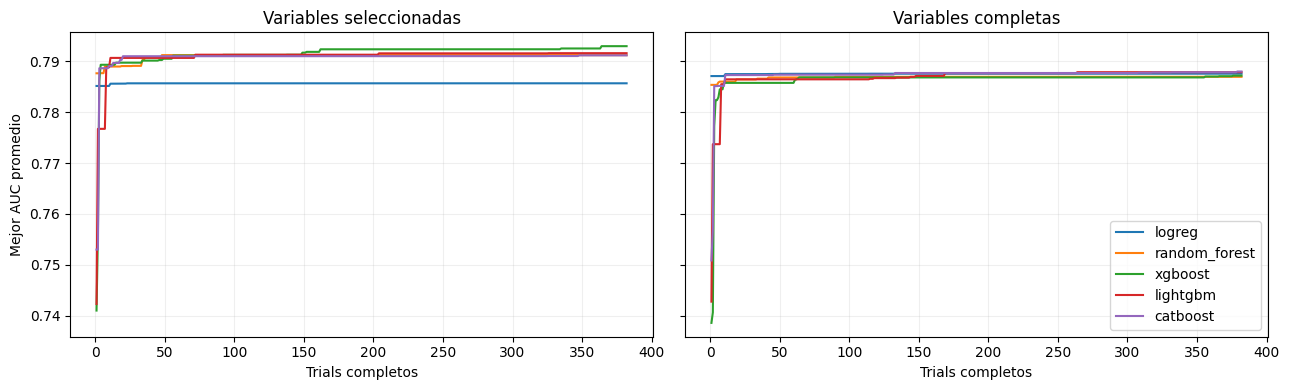

In [20]:
figura, ejes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for eje, conjunto in zip(ejes, conjuntos_variables):
    for algoritmo in ALGORITMOS:
        estudio = estudios[f"{algoritmo}__{conjunto}"]
        valores = [
            trial.value
            for trial in trials_completos(estudio)[:trials_comparables]
        ]
        eje.plot(range(1, len(valores) + 1), np.maximum.accumulate(valores), label=algoritmo)
    eje.set_title(f"Variables {conjunto}")
    eje.set_xlabel("Trials completos")
    eje.grid(alpha=0.2)
ejes[0].set_ylabel("Mejor AUC promedio")
ejes[1].legend()
figura.tight_layout()
figura.savefig(carpeta_resultados / "convergencia_optuna.png", dpi=160)
plt.show()

## 13. Resultados por estrategia y ventana

Resumimos cuántos trials comparables se evaluaron en cada combinación de algoritmo, conjunto de variables, estrategia y ventana, y el mejor AUC que alcanzaron.

Los hiperparámetros también varían entre estos trials. Esta tabla describe la búsqueda conjunta; no mide el efecto aislado del desbalance o de la ventana.

Conservamos el mejor trial de cada uno de los diez estudios como candidato individual para la selección final.

In [21]:
filas_exploracion = []
for nombre_estudio, estudio in estudios.items():
    for trial in trials_completos(estudio)[:trials_comparables]:
        filas_exploracion.append({
            "estudio": nombre_estudio,
            "estrategia": trial.params["estrategia"],
            "ventana": trial.params["ventana"],
            "auc_promedio": trial.value,
        })

tabla_exploracion = pd.DataFrame(filas_exploracion)
tabla_ventanas = (
    tabla_exploracion.groupby(["estudio", "estrategia", "ventana"], as_index=False)
    .agg(trials=("auc_promedio", "size"), mejor_auc=("auc_promedio", "max"))
)
tabla_ventanas.to_csv(carpeta_resultados / "estrategias_y_ventanas.csv", index=False)
configuraciones_candidatas = dict(configuraciones_optuna)
resultados_candidatos = dict(resultados_optuna)
tabla_candidatos = tabla_optuna.copy()
tabla_candidatos.to_csv(carpeta_resultados / "candidatos.csv", index=False)
display(tabla_ventanas.round(4))
display(tabla_candidatos.round(4))

,estudio,estrategia,ventana,trials,mejor_auc
0,catboost__completas,pesos_clase,24_meses,2,0.7805
1,catboost__completas,pesos_clase,36_meses,13,0.7869
2,catboost__completas,pesos_clase,48_meses,2,0.7856
3,catboost__completas,pesos_clase,toda_historia,3,0.7840
4,catboost__completas,sin_tratamiento,24_meses,12,0.7865
...,...,...,...,...,...
155,xgboost__seleccionadas,smote,toda_historia,4,0.7883
156,xgboost__seleccionadas,submuestreo,24_meses,2,0.7873
157,xgboost__seleccionadas,submuestreo,36_meses,4,0.7893
158,xgboost__seleccionadas,submuestreo,48_meses,13,0.7897


,estudio,algoritmo,conjunto,numero_variables,estrategia,ventana,trials_completos,trials_comparados,mejor_trial,auc_promedio,desviacion_auc,lift_promedio
0,logreg__seleccionadas,logreg,seleccionadas,6,smote,24_meses,383,382,91,0.7857,0.0097,2.1488
1,logreg__completas,logreg,completas,42,pesos_clase,36_meses,383,382,230,0.7876,0.0077,2.2577
2,random_forest__seleccionadas,random_forest,seleccionadas,6,sin_tratamiento,48_meses,383,382,47,0.7912,0.0092,2.2882
3,random_forest__completas,random_forest,completas,42,sin_tratamiento,toda_historia,383,382,91,0.7869,0.0092,2.2903
4,xgboost__seleccionadas,xgboost,seleccionadas,6,sin_tratamiento,48_meses,383,382,363,0.7930,0.0098,2.3025
5,xgboost__completas,xgboost,completas,42,pesos_clase,48_meses,383,382,375,0.7872,0.0094,2.2621
6,lightgbm__seleccionadas,lightgbm,seleccionadas,6,pesos_clase,36_meses,383,382,325,0.7916,0.0076,2.2784
7,lightgbm__completas,lightgbm,completas,42,pesos_clase,36_meses,383,382,263,0.7879,0.0081,2.2857
8,catboost__seleccionadas,catboost,seleccionadas,6,smote,48_meses,383,382,347,0.7912,0.0094,2.2636
9,catboost__completas,catboost,completas,42,sin_tratamiento,36_meses,382,382,378,0.7880,0.0087,2.2774


## 14. Selección del modelo individual

Comparamos los mejores trials de los diez estudios. Elegimos por AUC promedio, lift mensual y menor número de variables, usando las tolerancias fijadas antes de entrenar y los valores sin redondear.

La configuración ganadora contiene un algoritmo, un conjunto de variables, una estrategia de desbalance, una ventana y sus hiperparámetros.

Estas métricas provienen de bloques utilizados para tomar decisiones. Buscar más configuraciones puede aumentar su optimismo; la evaluación final y la incertidumbre quedan para la fase 05.

In [22]:
tabla_finalistas = tabla_candidatos.copy()
ganador = elegir_candidato(tabla_finalistas, ["numero_variables"])
nombre_ganador = ganador["estudio"]
configuracion_ganadora = configuraciones_candidatas[nombre_ganador]
resultado_ganador = resultados_candidatos[nombre_ganador]
tabla_finalistas.to_csv(carpeta_resultados / "finalistas.csv", index=False)

display(tabla_finalistas.sort_values("auc_promedio", ascending=False).round(4))
print(f"Modelo elegido: {nombre_ganador}")
print(f"Desbalance: {configuracion_ganadora['estrategia']}; ventana: {ganador['ventana']}")
print(f"AUC promedio de validación: {resultado_ganador['auc_promedio']:.4f}")
print(f"Lift mensual promedio: {resultado_ganador['lift_promedio']:.2f}")
display(pd.DataFrame({
    "bloque": range(1, NUMERO_BLOQUES + 1),
    "auc": resultado_ganador["auc_por_bloque"],
}).round(4))
display(resultado_ganador["lift_por_mes"].round(4))

,estudio,algoritmo,conjunto,numero_variables,estrategia,ventana,trials_completos,trials_comparados,mejor_trial,auc_promedio,desviacion_auc,lift_promedio
4,xgboost__seleccionadas,xgboost,seleccionadas,6,sin_tratamiento,48_meses,383,382,363,0.7930,0.0098,2.3025
6,lightgbm__seleccionadas,lightgbm,seleccionadas,6,pesos_clase,36_meses,383,382,325,0.7916,0.0076,2.2784
2,random_forest__seleccionadas,random_forest,seleccionadas,6,sin_tratamiento,48_meses,383,382,47,0.7912,0.0092,2.2882
8,catboost__seleccionadas,catboost,seleccionadas,6,smote,48_meses,383,382,347,0.7912,0.0094,2.2636
9,catboost__completas,catboost,completas,42,sin_tratamiento,36_meses,382,382,378,0.7880,0.0087,2.2774
7,lightgbm__completas,lightgbm,completas,42,pesos_clase,36_meses,383,382,263,0.7879,0.0081,2.2857
1,logreg__completas,logreg,completas,42,pesos_clase,36_meses,383,382,230,0.7876,0.0077,2.2577
5,xgboost__completas,xgboost,completas,42,pesos_clase,48_meses,383,382,375,0.7872,0.0094,2.2621
3,random_forest__completas,random_forest,completas,42,sin_tratamiento,toda_historia,383,382,91,0.7869,0.0092,2.2903
0,logreg__seleccionadas,logreg,seleccionadas,6,smote,24_meses,383,382,91,0.7857,0.0097,2.1488


Modelo elegido: xgboost__seleccionadas
Desbalance: sin_tratamiento; ventana: 48_meses
AUC promedio de validación: 0.7930
Lift mensual promedio: 2.30


,bloque,auc
0,1,0.8014
1,2,0.7915
2,3,0.8015
3,4,0.7775


,mes,filas_validacion,seleccionadas,tasa_churn_mes,precision_seleccionadas,lift
0,2024-02-01,239,23,0.2385,0.4348,1.8230
1,2024-03-01,242,24,0.2893,0.7083,2.4488
2,2024-04-01,258,25,0.3178,0.7600,2.3912
3,2024-05-01,267,26,0.2846,0.7308,2.5673
4,2024-06-01,250,25,0.2240,0.5600,2.5000
5,2024-07-01,283,28,0.2580,0.6786,2.6306
6,2024-08-01,296,29,0.2905,0.5862,2.0176
7,2024-09-01,281,28,0.3381,0.6786,2.0071
8,2024-10-01,247,24,0.2672,0.7083,2.6509
9,2024-11-01,265,26,0.3245,0.7308,2.2518


## 15. Guardado de la configuración y ajuste final

Con la elección fijada, ajustamos un único modelo sobre desarrollo, respetando su ventana, su escalado y su tratamiento del desbalance. Si usa pesos de clase, el peso se calcula con este entrenamiento final.

modelo_final.joblib guarda un diccionario con el pipeline entrenado en estimador, la lista variables y la especificacion completa. Por ejemplo, la fase 05 podrá obtener probabilidades con el estimador cargado y las columnas guardadas.

Los artefactos tienen formato v2 y se guardan en la carpeta del experimento. La fase 05 deberá cargar esta nueva ruta. La carga del pipeline no requiere funciones de archivos .py del proyecto.

In [23]:
fecha_ejecucion = datetime.now(timezone.utc).isoformat()
especificacion_final = {
    "formato": "modelado_v2_individual",
    "experimento": identificador_experimento,
    "fecha_utc": fecha_ejecucion,
    "max_trials_por_estudio": MAX_TRIALS_POR_ESTUDIO,
    "trials_comparados_por_estudio": trials_comparables,
    "protocolo": protocolo_experimento,
    "criterio": {
        "metrica": "auc_promedio",
        "tolerancia_auc": TOLERANCIA_AUC,
        "desempate": "lift_mensual_top_10",
        "tolerancia_lift": TOLERANCIA_LIFT,
        "simplicidad": "numero_variables",
    },
    "candidatos": {
        nombre: {
            **configuracion,
            **metricas_resumen(resultados_candidatos[nombre]),
            "auc_por_bloque": resultados_candidatos[nombre]["auc_por_bloque"],
        }
        for nombre, configuracion in configuraciones_candidatas.items()
    },
    "final": {
        "nombre": nombre_ganador,
        "tipo": "individual",
        **configuracion_ganadora,
        "numero_variables": int(ganador["numero_variables"]),
        **metricas_resumen(resultado_ganador),
        "auc_por_bloque": resultado_ganador["auc_por_bloque"],
    },
}

ruta_especificacion = carpeta_resultados / "modelo_final.json"
ruta_especificacion.write_text(
    json.dumps(especificacion_final, ensure_ascii=False, indent=2, allow_nan=False),
    encoding="utf-8",
)
resultado_ganador["lift_por_mes"].to_csv(
    carpeta_resultados / "lift_mensual_final.csv", index=False
)
np.savez_compressed(
    carpeta_resultados / "probabilidades_oof_final.npz",
    probabilidades_oof=resultado_ganador["probabilidades_oof"],
)
print(f"Configuración guardada: {ruta_especificacion}")

Configuración guardada: resultados_v2/ceacafa20f395276/modelo_final.json


In [24]:
entrenamiento_final = recortar_entrenamiento(
    datos_desarrollo, configuracion_ganadora["ventana_meses"]
)
modelo_final = preparar_modelo(
    construir_modelo(
        configuracion_ganadora["algoritmo"], configuracion_ganadora["parametros"]
    ),
    entrenamiento_final[COLUMNA_OBJETIVO],
    configuracion_ganadora["estrategia"],
    configuracion_ganadora["parametros"].get("intensidad_peso", 1.0),
)
print(f"Ajuste final sobre desarrollo: {nombre_ganador}", flush=True)
modelo_final.fit(
    entrenamiento_final[configuracion_ganadora["variables"]],
    entrenamiento_final[COLUMNA_OBJETIVO],
)

ruta_modelo = carpeta_resultados / "modelo_final.joblib"
ruta_modelo_temporal = ruta_modelo.with_suffix(".tmp.joblib")
joblib.dump({
    "formato": "modelado_v2_individual",
    "especificacion": especificacion_final,
    "estimador": modelo_final,
    "variables": configuracion_ganadora["variables"],
    "entrenamiento_desde": entrenamiento_final["mes_obs"].min().strftime("%Y-%m"),
    "entrenamiento_hasta": entrenamiento_final["mes_obs"].max().strftime("%Y-%m"),
    "filas_entrenamiento": len(entrenamiento_final),
}, ruta_modelo_temporal, compress=3)
ruta_modelo_temporal.replace(ruta_modelo)
print(f"Modelo guardado: {ruta_modelo}")

Ajuste final sobre desarrollo: xgboost__seleccionadas
Modelo guardado: resultados_v2/ceacafa20f395276/modelo_final.joblib


## 16. Reporte de la corrida

El reporte resume el tratamiento del desbalance, los diez estudios, las ventanas y los finalistas con los resultados calculados en esta ejecución. También deja las rutas de la configuración y del modelo entrenado.

El OOT queda fuera de los ajustes, las métricas y las decisiones de este notebook. Esto no convierte el OOT histórico del proyecto en un conjunto nuevo: sus evaluaciones anteriores están documentadas en AVANCE.md.

La siguiente fase es cargar los artefactos v2 para la verificación complementaria y la evaluación OOT, incluyendo el intervalo de confianza del AUC mediante bootstrap por vendedora. La dispersión entre los cuatro bloques mostrada aquí no sustituye ese intervalo.

In [ ]:
def tabla_markdown(tabla):
    tabla = tabla.copy()
    for columna in tabla.select_dtypes(include="floating").columns:
        tabla[columna] = tabla[columna].map(lambda valor: f"{valor:.4f}")
    filas = [
        "| " + " | ".join(map(str, tabla.columns)) + " |",
        "| " + " | ".join(["---"] * len(tabla.columns)) + " |",
    ]
    filas.extend(
        "| " + " | ".join(map(str, fila)) + " |"
        for fila in tabla.itertuples(index=False, name=None)
    )
    return "\n".join(filas)


reporte = "\n\n".join([
    "# Modelado v2",
    f"Experimento: {identificador_experimento}. Fecha UTC: {fecha_ejecucion}.",
    "Búsqueda sin límite de tiempo. "
    f"Trials comparados por estudio: {trials_comparables}; "
    f"{len(estudios)} estudios. Objetivo: AUC promedio de {NUMERO_BLOQUES} bloques.",
    "## Optuna",
    tabla_markdown(tabla_optuna),
    "## Búsqueda conjunta de estrategias y ventanas",
    tabla_markdown(tabla_ventanas),
    "## Candidatos individuales",
    tabla_markdown(tabla_candidatos),
    "## Selección entre modelos individuales",
    tabla_markdown(tabla_finalistas.sort_values("auc_promedio", ascending=False)),
    "## Configuración seleccionada",
    f"Modelo: {nombre_ganador}. "
    f"AUC promedio: {resultado_ganador['auc_promedio']:.6f}. "
    f"Desviación entre bloques: {resultado_ganador['desviacion_auc']:.6f}. "
    f"Lift mensual: {resultado_ganador['lift_promedio']:.6f}.",
    f"Regla fijada antes de entrenar: tolerancia AUC {TOLERANCIA_AUC}, "
    f"tolerancia lift {TOLERANCIA_LIFT}; después menos variables.",
    tabla_markdown(resultado_ganador["lift_por_mes"]),
    "## Artefactos",
    f"Configuración: {ruta_especificacion.resolve()}.",
    f"Pipeline entrenado sobre desarrollo: {ruta_modelo.resolve()}.",
    f"Estudios y trials: {ruta_base_optuna.resolve()} y {carpeta_trials.resolve()}.",
    "Estas métricas se usaron para seleccionar configuraciones; no son una "
    "estimación independiente del desempeño final. El OOT no se evaluó en esta corrida. "
    "Las evaluaciones históricas del OOT están documentadas en AVANCE.md. "
    "Queda pendiente evaluar el artefacto v2 y estimar incertidumbre en la fase 05.",
])

carpeta_reportes = Path("../reports")
carpeta_reportes.mkdir(parents=True, exist_ok=True)
ruta_reporte = carpeta_reportes / f"modelado_v2_{identificador_experimento}.md"
ruta_reporte.write_text(reporte + "\n", encoding="utf-8")
(carpeta_resultados / "reporte.md").write_text(reporte + "\n", encoding="utf-8")

Path("resultados_v2/ultima_corrida.json").write_text(
    json.dumps({
        "experimento": identificador_experimento,
        "fecha_utc": fecha_ejecucion,
        "carpeta_resultados": str(carpeta_resultados.resolve()),
        "configuracion": str(ruta_especificacion.resolve()),
        "modelo": str(ruta_modelo.resolve()),
        "reporte": str(ruta_reporte.resolve()),
    }, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(f"Corrida completa. Modelo elegido: {nombre_ganador}")
print(f"Resultados: {carpeta_resultados.resolve()}")
print(f"Reporte: {ruta_reporte.resolve()}")